In [1]:
# =============================================================================
# Projeto: Análise de Recomendações Pedagógicas para o Uso de Inteligência
#          Artificial Generativa na Educação a Distância por meio de PLN e LLMs
# Disciplina: Inteligência Artificial - 7º N - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrante: Daniel Ribeiro Pauleti - RA 10723162 - 10723162@mackenzista.com.br
#
# Arquivo: notebooks/03_analise_exploratoria.ipynb
# Síntese: análise exploratória do corpus: distribuição temporal, idiomas, tipos,
#          fontes, citações, tamanho dos resumos, palavras-chave e termos frequentes.
#
# Histórico de alterações:
#   2026-09-25 - Daniel Ribeiro Pauleti - Versão inicial.
# =============================================================================

# 03 — Análise exploratória do corpus

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_colwidth", 90)
import matplotlib.pyplot as plt
AZUL = "#2a78d6"                      # série única
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.family": "DejaVu Sans"})
FIG = RAIZ / "figuras"; FIG.mkdir(exist_ok=True)
def salvar(nome): plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", bbox_inches="tight"); plt.show()
corpus = pd.read_csv(RAIZ / "data/processed/corpus.csv")
print(corpus.shape)
corpus[["ano", "citacoes", "n_palavras_resumo"]].describe().round(1)

(208, 19)


,ano,citacoes,n_palavras_resumo
count,208.0,208.0,208.0
mean,2025.0,4.4,226.7
std,0.9,12.9,110.5
min,2023.0,0.0,57.0
25%,2024.0,0.0,165.8
50%,2025.0,0.0,199.5
75%,2026.0,2.0,247.2
max,2026.0,92.0,817.0


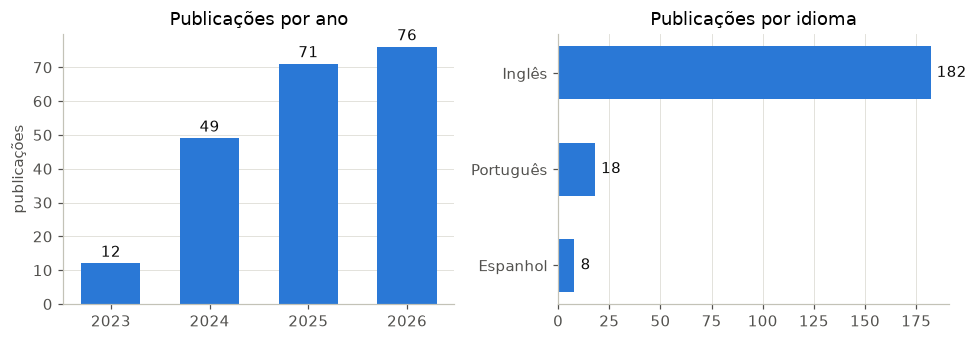

Observação: 2026 contém apenas publicações indexadas até a data da coleta.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
ano = corpus["ano"].value_counts().sort_index()
axes[0].bar(ano.index.astype(str), ano.values, color=AZUL, width=0.6)
for x, v in zip(ano.index.astype(str), ano.values): axes[0].text(x, v + 2, v, ha="center", color="#0b0b0b")
axes[0].set_title("Publicações por ano"); axes[0].set_ylabel("publicações"); axes[0].grid(axis="x", visible=False)
idi = corpus["idioma"].map({"en": "Inglês", "pt": "Português", "es": "Espanhol"}).value_counts()
axes[1].barh(idi.index[::-1], idi.values[::-1], color=AZUL, height=0.55)
for y, v in zip(idi.index[::-1], idi.values[::-1]): axes[1].text(v + 3, y, v, va="center", color="#0b0b0b")
axes[1].set_title("Publicações por idioma"); axes[1].grid(axis="y", visible=False)
salvar("fig1_ano_idioma")
print("Observação: 2026 contém apenas publicações indexadas até a data da coleta.")

In [4]:
pd.crosstab(corpus["ano"], corpus["tipo"], margins=True, margins_name="Total")

tipo,article,book-chapter,conference-paper,preprint,review,Total
ano,,,,,,
2023,9,1,2,0,0,12
2024,31,4,11,3,0,49
2025,49,4,15,2,1,71
2026,56,1,9,6,4,76
Total,145,10,37,11,5,208


In [5]:
print("Acesso aberto:", corpus["acesso_aberto"].mean().round(3))
print("Fontes distintas:", corpus["fonte"].nunique(), "| sem fonte:", corpus["fonte"].isna().sum())
corpus["fonte"].value_counts().head(10).rename("publicações").to_frame()

Acesso aberto: 0.846
Fontes distintas: 133 | sem fonte: 38


,publicações
fonte,
Zenodo (CERN European Organization for Nuclear Research),8
arXiv (Cornell University),5
International Journal of Research and Innovation in Social Science,5
Open Praxis,4
Online Journal of Communication and Media Technologies,2
Distance Learning,2
Caderno Pedagógico,2
Frontiers in Computer Science,2
IAES International Journal of Artificial Intelligence,2


In [6]:
corpus["area"].value_counts().head(8).rename("publicações").to_frame()

,publicações
area,
Computer Science,104
Social Sciences,44
Medicine,41
Psychology,7
Arts and Humanities,4
"Business, Management and Accounting",2
Engineering,1
"Biochemistry, Genetics and Molecular Biology",1


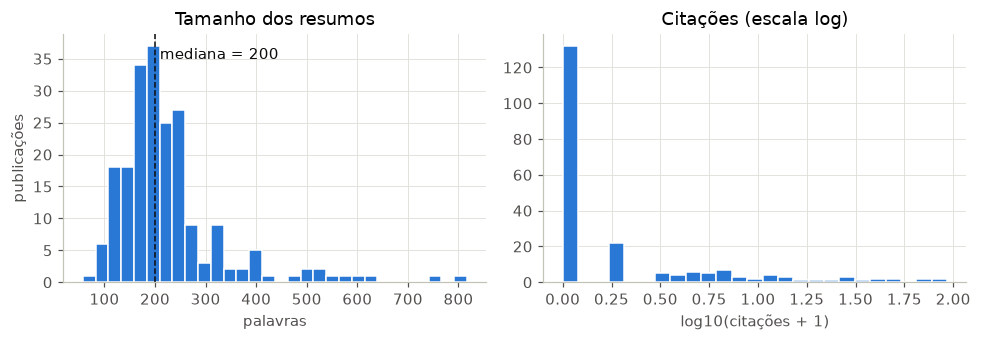

Publicações sem nenhuma citação: 0.635


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(corpus["n_palavras_resumo"], bins=30, color=AZUL, edgecolor="white")
axes[0].axvline(corpus["n_palavras_resumo"].median(), color="#0b0b0b", ls="--", lw=1)
axes[0].text(corpus["n_palavras_resumo"].median() + 10, axes[0].get_ylim()[1] * 0.9,
             f"mediana = {corpus['n_palavras_resumo'].median():.0f}", color="#0b0b0b")
axes[0].set_title("Tamanho dos resumos"); axes[0].set_xlabel("palavras"); axes[0].set_ylabel("publicações")
import numpy as np
axes[1].hist(np.log10(corpus["citacoes"] + 1), bins=25, color=AZUL, edgecolor="white")
axes[1].set_title("Citações (escala log)"); axes[1].set_xlabel("log10(citações + 1)")
salvar("fig2_resumos_citacoes")
print("Publicações sem nenhuma citação:", (corpus["citacoes"] == 0).mean().round(3))

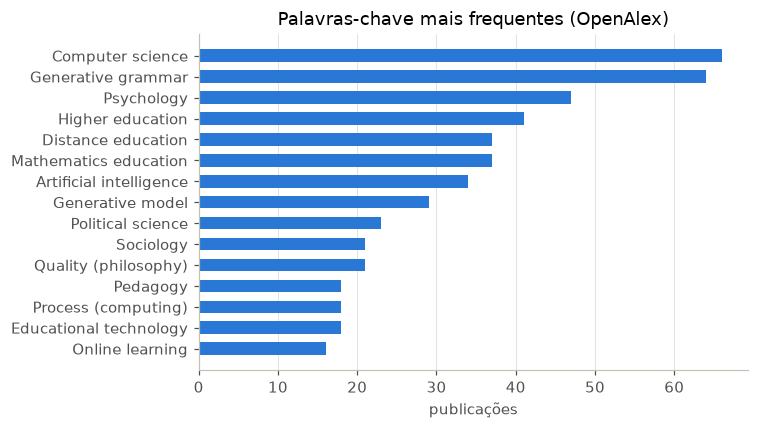

In [8]:
# Palavras-chave atribuídas pelo OpenAlex
kw = corpus["palavras_chave"].dropna().str.split("; ").explode()
kw_top = kw.value_counts().head(15)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(kw_top.index[::-1], kw_top.values[::-1], color=AZUL, height=0.6)
ax.set_title("Palavras-chave mais frequentes (OpenAlex)"); ax.set_xlabel("publicações"); ax.grid(axis="y", visible=False)
salvar("fig3_palavras_chave")

In [9]:
# Termos (uni e bigramas) mais frequentes nos resumos em inglês, sem stopwords
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
extra = {"study", "research", "paper", "use", "using", "used", "results", "findings", "article",
         "based", "also", "chapter", "data", "analysis", "approach", "new", "provide", "including"}
en = corpus[corpus["idioma"] == "en"]
cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | extra), ngram_range=(1, 2), min_df=3,
                     token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z-]+\b")
X = cv.fit_transform(en["texto"])
freq_doc = pd.Series((X > 0).sum(axis=0).A1, index=cv.get_feature_names_out()).sort_values(ascending=False)
print("Vocabulário (en, min_df=3):", len(freq_doc))
freq_doc.head(25).rename("documentos").to_frame().T

Vocabulário (en, min_df=3): 2103


,learning,education,ai,intelligence,artificial,artificial intelligence,generative,distance,students,higher,...,chatgpt,educational,tools,generative artificial,language,challenges,student,design,development,potential
documentos,172,161,133,125,124,123,123,122,110,103,...,75,73,68,66,66,65,65,65,64,62


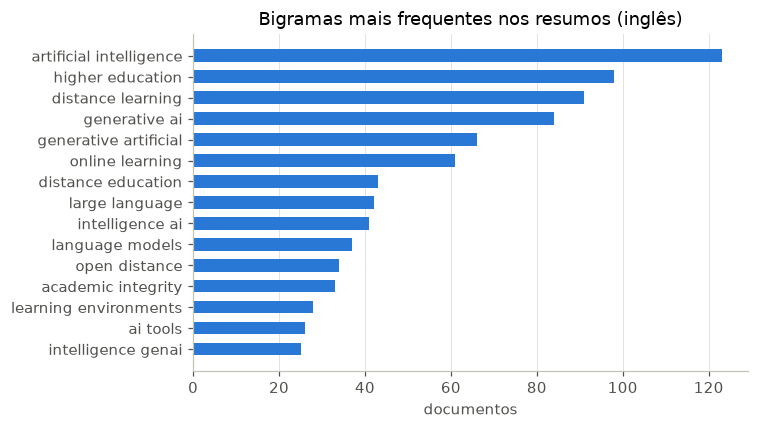

In [10]:
bigr = freq_doc[[" " in t for t in freq_doc.index]].head(15)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(bigr.index[::-1], bigr.values[::-1], color=AZUL, height=0.6)
ax.set_title("Bigramas mais frequentes nos resumos (inglês)"); ax.set_xlabel("documentos"); ax.grid(axis="y", visible=False)
salvar("fig4_bigramas")

In [11]:
# Ferramentas/modelos citados nos textos
import re
ferramentas = {"ChatGPT": r"chat ?gpt", "GPT-4/4o": r"gpt[- ]?4", "Gemini/Bard": r"gemini|\bbard\b",
               "Copilot": r"copilot", "Claude": r"\bclaude\b", "LLM (genérico)": r"large language model|\bllms?\b"}
pd.Series({k: corpus["texto"].str.contains(v, flags=re.I).sum() for k, v in ferramentas.items()}).rename("documentos").to_frame()

,documentos
ChatGPT,90
GPT-4/4o,8
Gemini/Bard,16
Copilot,10
Claude,8
LLM (genérico),45
